# CP1/CP4 — Problema, dados e indicadores
**Grupo:** Integrante 1 identificação no pacote privado; Integrante 2 identificação no pacote privado;
Integrante 3 identificação no pacote privado; Integrante 4 identificação no pacote privado; Integrante 5 identificação no pacote privado.

Fonte de distribuição informada no CP1 original: https://www.kaggle.com/datasets/dongeorge/beer-consumption-sao-paulo?resource=download .
Consulta da página e leitura da cópia local: 27/10/2026. A data do download original não está registrada; não foi inventada.
Base diária de São Paulo, 01/01/2015 a 31/12/2015. Sete colunas: Data, temperaturas média/mínima/máxima (°C),
precipitação (mm), indicador de fim de semana (0/1), consumo (rótulo original: litros).
Não há dados individuais, faixa etária, horários ou feriados rotulados. A alegação original sobre estudantes foi removida por falta de evidência.
Unidade e representatividade: os cálculos preservam os valores do CSV, sem multiplicar por mil. A escala física e a procedência primária precisam ser confirmadas antes de uso operacional; a página de distribuição não equivale a uma coleta primária oficial.
Uma única fonte é usada, portanto não há integração entre bases.
Tema: economia e planejamento de estoque de bebidas na amostra de São Paulo. Os dados descrevem 2015, não a situação de 2026.

## Problema e perguntas
Como clima e calendário se associam ao consumo diário observado, para apoiar planejamento de estoque?
1. Qual a associação entre temperatura máxima e consumo?
2. Como o consumo médio difere entre dias com e sem chuva?
3. Qual a diferença de consumo entre dias úteis e fins de semana?
São associações observacionais: não permitem concluir influência causal ou comportamento individual.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT/'analysis.py').exists():
    raise RuntimeError('Execute o notebook a partir da pasta pacote_revisao')
sys.path.insert(0, str(ROOT))
from analysis import *
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
df, quality = load_data()
display(pd.Series(quality, name='Qualidade'))
display(df.head())

linhas_originais                                                         941
linhas_vazias_removidas                                                  576
linhas_validas                                                           365
ausentes                                                                   0
duplicadas                                                                 0
sha256_csv                 57a1df4479336ac4a6510fc7cc84f3a37eff88d0bdb915...
Name: Qualidade, dtype: object

,Data,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
0,2015-01-01,27.30,23.9,32.5,0.0,0,25.461
1,2015-01-02,27.02,24.5,33.5,0.0,0,28.972
2,2015-01-03,24.82,22.4,29.9,0.0,1,30.814
3,2015-01-04,23.98,21.5,28.6,1.2,1,29.799
4,2015-01-05,23.82,21.0,28.3,0.0,0,28.900


## Qualidade e preparação
Removemos somente linhas totalmente vazias; convertimos vírgulas decimais, datas e tipos. Dados parcialmente ausentes, duplicações ou inconsistências causam erro explícito. Não descartamos linhas malformadas silenciosamente.

In [2]:
display(df.describe(include='all'))
display(df[FEATURES+[TARGET]].corr())

,Data,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
count,365,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000
mean,2015-07-02 00:00:00,21.226356,17.461370,26.611507,5.196712,0.284932,25.401367
min,2015-01-01 00:00:00,12.900000,10.600000,14.500000,0.000000,0.000000,14.343000
25%,2015-04-02 00:00:00,19.020000,15.300000,23.800000,0.000000,0.000000,22.008000
50%,2015-07-02 00:00:00,21.380000,17.900000,26.900000,0.000000,0.000000,24.867000
75%,2015-10-01 00:00:00,23.280000,19.600000,29.400000,3.200000,1.000000,28.631000
max,2015-12-31 00:00:00,28.860000,24.500000,36.500000,94.800000,1.000000,37.937000
std,NaN,3.180108,2.826185,4.317366,12.417844,0.452001,4.399143


,Temperatura Media (C),Temperatura Minima (C),Temperatura Maxima (C),Precipitacao (mm),Final de Semana,Consumo de cerveja (litros)
Temperatura Media (C),1.000000,0.862752,0.922513,0.024416,-0.050803,0.574615
Temperatura Minima (C),0.862752,1.000000,0.672929,0.098625,-0.059534,0.392509
Temperatura Maxima (C),0.922513,0.672929,1.000000,-0.049305,-0.040258,0.642672
Precipitacao (mm),0.024416,0.098625,-0.049305,1.000000,0.001587,-0.193784
Final de Semana,-0.050803,-0.059534,-0.040258,0.001587,1.000000,0.505981
Consumo de cerveja (litros),0.574615,0.392509,0.642672,-0.193784,0.505981,1.000000


## KPIs calculados e justificativa
KPI 1: correlação de Pearson entre temperatura máxima e consumo, para medir associação linear.
KPI 2: consumo médio com/sem chuva (precipitação > 0), para comparar condições meteorológicas.
KPI 3: consumo médio por tipo de dia e diferença percentual (média fim de semana / média dia útil − 1) × 100, para dimensionar variação de estoque.
Os denominadores são os dias observados em cada grupo; não são medidas de consumo per capita.

In [3]:
k=indicators(df)
display(pd.Series(k,name='Valor'))
display(df.groupby('Final de Semana')[TARGET].agg(['count','mean','std']))
display(df.groupby(df['Precipitacao (mm)'].gt(0))[TARGET].agg(['count','mean','std']))

dias                         365.000000
consumo_medio                 25.401367
consumo_total_periodo       9271.499000
media_fim_semana              28.922721
media_dia_util                23.998222
diferenca_fim_semana_pct      20.520266
media_com_chuva               24.617769
media_sem_chuva               25.929757
correlacao_tmax                0.642672
Name: Valor, dtype: float64

,count,mean,std
Final de Semana,,,
0,261,23.998222,3.787527
1,104,28.922721,3.830191


,count,mean,std
Precipitacao (mm),,,
False,218,25.929757,4.341602
True,147,24.617769,4.381487


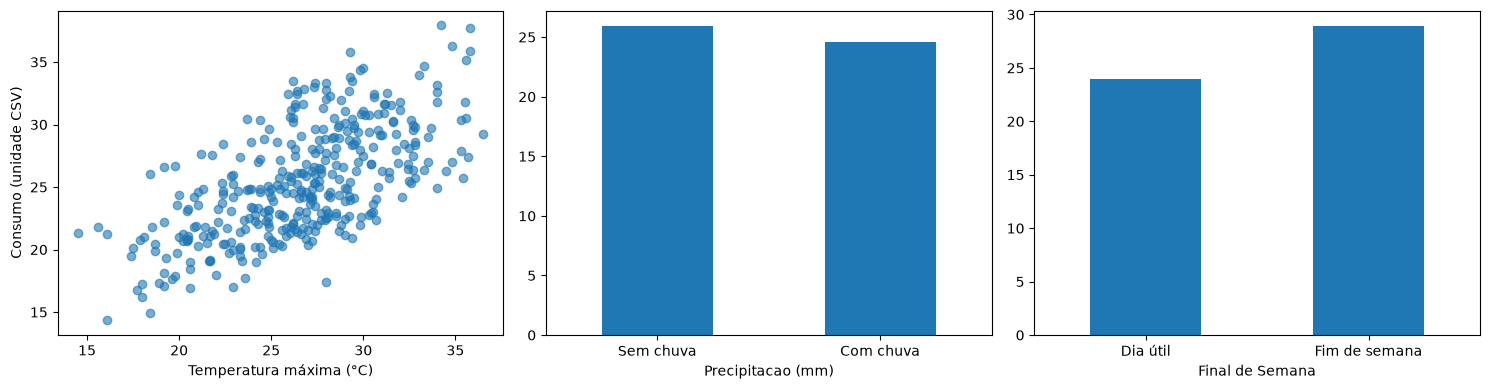

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].scatter(df[FEATURES[2]],df[TARGET],alpha=.6); axes[0].set(xlabel='Temperatura máxima (°C)',ylabel='Consumo (unidade CSV)')
df.groupby(df['Precipitacao (mm)'].gt(0))[TARGET].mean().rename(index={False:'Sem chuva',True:'Com chuva'}).plot.bar(ax=axes[1],rot=0)
df.groupby('Final de Semana')[TARGET].mean().rename(index={0:'Dia útil',1:'Fim de semana'}).plot.bar(ax=axes[2],rot=0)
plt.tight_layout(); plt.show()

## Respostas e decisão

In [5]:
display(Markdown(f"No recorte de 2015, o consumo médio foi **{k['consumo_medio']:.3f}**, na unidade do CSV. A correlação com temperatura máxima foi **{k['correlacao_tmax']:.3f}**; a média com chuva foi **{k['media_com_chuva']:.3f}**, e sem chuva **{k['media_sem_chuva']:.3f}**. Fins de semana registraram **{k['media_fim_semana']:.3f}**, contra **{k['media_dia_util']:.3f}** em dias úteis, diferença de **{k['diferenca_fim_semana_pct']:.2f}%**."))

No recorte de 2015, o consumo médio foi **25.401**, na unidade do CSV. A correlação com temperatura máxima foi **0.643**; a média com chuva foi **24.618**, e sem chuva **25.930**. Fins de semana registraram **28.923**, contra **23.998** em dias úteis, diferença de **20.52%**.

Os três KPIs se complementam: temperatura resume associação contínua; chuva e calendário facilitam planejamento por cenário. Podem orientar hipóteses de estoque, mas a base pequena e histórica exige validação em dados atuais do estabelecimento. Horários e feriados não foram analisados, pois faltam variáveis adequadas. Na etapa seguinte, a modelagem combina os fatores e mede o erro em dias posteriores, sem atribuir causalidade.